# Visium HD: Lazy Bins, Bespoke Rebinning, and Getting Real Cells

Visium HD is different from every other platform in this library in one fundamental way: it is sequencing-based, not imaging-based, so it ships **no cell segmentation**. Instead of segmented cells, a run produces a regular grid of 2µm square "bins" — millions of them for a full tissue section. Two consequences follow directly from that:

1. **The bin matrix must stay lazy.** A full-resolution bin x gene matrix is too large to load by default, so `io.read_visium_hd` leaves it on disk and hands back a path descriptor instead — the same trick `ImageSpec` uses for images, just applied to a count matrix.
2. **Getting to "cell x gene" is a deliberate extra step**, not something the reader does for you — unless Space Ranger's own on-board segmentation (v4.0+) is present, in which case it *is* loaded automatically as the primary modality, exactly like Xenium/MERSCOPE/CosMx always are.

This notebook works through both situations: a tiny dataset that already has native segmentation, and a larger real dataset that doesn't — where the `seg.segment_bin2cell` / `seg.assign_bins` bin2cell reimplementation takes over.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab
import scanpy as sc

INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib
INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## 1. Load the tiny dataset — native segmentation, out of the box

`ab.datasets.visium_hd_tiny()` downloads a small (~297 MB) Space Ranger v4.0.1 run that 10x itself built specifically for automated smoke testing. Space Ranger v4.0+ can run its own on-board H&E-based nucleus/cell segmentation, and this run has it — so `io.read_visium_hd` finds `segmented_outputs/` automatically and loads it as `mdata['visium_hd_cells']`, making it the primary (default) modality immediately, with no extra step. The lazy 2µm bins are still there too, under `mdata['visium_hd_bins']`, for anything that needs bin-level resolution.

In [2]:
mdata_tiny = ab.datasets.visium_hd_tiny()

print("modalities:", list(mdata_tiny.mod.keys()))
print("default modality:", mdata_tiny.uns['default_modality'])
ab.summary(mdata_tiny)

INFO:astrolabe.io._visium_hd:Reading Visium HD run 'visium_hd_tiny' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\visium_hd_tiny\outs
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\mudata\_core\mudata.py:1416: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=0, join_common=join_common)
INFO:astrolabe.io._visium_hd:Loaded 330035 bins × 32285 features (lazy — X not materialized; pixel_size=1.0031 µm)
INFO:astrolabe.io._he:Reading H&E 'cytassist_image' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\visium_hd_tiny\outs\spatial\cytassist_image.tiff
INFO:astrolabe.io._he:Loaded H&E: pixel_size=1.0031 µm

modalities: ['visium_hd_bins', 'he', 'visium_hd_cells']
default modality: visium_hd_cells


Library ID,Source,Images
visium_hd_tiny,.astrolabe_cache\datasets\visium_hd_tiny\outs,none
cytassist_image,.astrolabe_cache\datasets\visium_hd_tiny\outs\spatial\cytassist_image.tiff,full · 3ch · 3000×3200×3


`mdata['visium_hd_bins'].X` is `None` — that's the lazy state, not a bug. The `obs`/`obsm['spatial']` columns (`array_row`, `array_col`, `in_tissue`, bin centroids in µm) come from `tissue_positions.parquet`, which is small enough to load in full even at millions of rows; only the actual count matrix is deferred. `mdata['visium_hd_cells']`, by contrast, is a normal eager cell x gene `AnnData` — Space Ranger's own segmentation output is cell-sized, not bin-sized, so there's no reason to keep it lazy.

The first spatial plot in this notebook: `.show()` is required before anything renders, `+` overlays the H&E image under the cell points, and `|` puts the bin-level and cell-level views side by side.

C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pl\_spatial.py:1898: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  sc = ax.scatter(


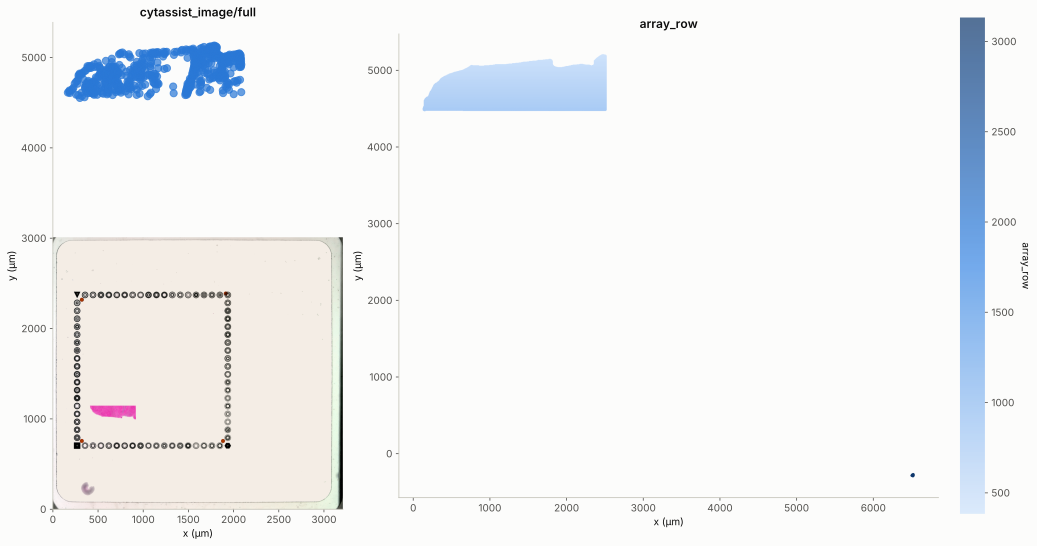

In [3]:
cells_panel = ab.pl.points(mdata_tiny, modality='visium_hd_cells')
if 'he' in mdata_tiny.mod:
    cells_panel = ab.pl.image(mdata_tiny, modality='he') + cells_panel

(
    cells_panel
    | ab.pl.points(mdata_tiny, modality='visium_hd_bins', color='array_row')
).show()

## 2. Resolution is a choice, not a fixed property of the data

`io.read_visium_hd` only ever reads the native **2µm** resolution — there is no `bin_size=` parameter. Space Ranger itself ships pre-computed 8µm and 16µm binned matrices too (larger bins, more counts per bin, less spatial precision — useful when per-bin sparsity is a bigger problem than resolution), but astrolabe treats getting to those as a deliberate, computed step rather than a second file to read: `tl.rebin_visium_hd(mdata, target_bin_um=...)` re-derives any bin size that's an integer multiple of the native one, by grouping bins on `array_row // factor`, `array_col // factor` — the exact rule Space Ranger itself uses internally, which is also why it works for non-standard sizes like `4` or `32` that Space Ranger never ships.

The result is attached as a new sibling modality (`mdata['visium_hd_bins_8um']`) without touching `default_modality` — it's a derived, opt-in view, not a replacement for the 2µm data it's built from.

In [4]:
rebinned = ab.tl.rebin_visium_hd(mdata_tiny, target_bin_um=8.0)
print(f"2µm bins: {mdata_tiny['visium_hd_bins'].n_obs}  ->  8µm bins: {rebinned.n_obs}")
print("attached as:", [k for k in mdata_tiny.mod if k.startswith('visium_hd_bins_')])

ab.pl.points(mdata_tiny, modality='visium_hd_bins_8um', color='n_bins').show()

INFO:astrolabe.tl._visium_hd:rebin_visium_hd: bin matrix not yet materialized; loading the full matrix via pp.load_bin_counts.
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
INFO:astrolabe.tl._visium_hd:rebin_visium_hd: 330035 native 2.0µm bins → 20830 bins at 8.0µm
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\mudata\_core\mudata.py:1

2µm bins: 330035  ->  8µm bins: 20830
attached as: ['visium_hd_bins_8um']


## 3. The real dataset — no native segmentation, so bin2cell takes over

`ab.datasets.visium_hd()` downloads a real public run (10x's Visium HD Mouse Small Intestine, Space Ranger 3.0.0) that predates Space Ranger v4.0's on-board segmentation. `default_modality` stays `'visium_hd_bins'` after loading — there is no cell-level modality yet, and getting one is an explicit next step, not something the reader guesses at.

In [5]:
mdata = ab.datasets.visium_hd()
print("modalities:", list(mdata.mod.keys()))
print("default modality:", mdata.uns['default_modality'])

INFO:astrolabe.io._visium_hd:Reading Visium HD run 'visium_hd' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\visium_hd\outs
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\mudata\_core\mudata.py:1416: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=0, join_common=join_common)
INFO:astrolabe.io._visium_hd:Loaded 5479660 bins × 19059 features (lazy — X not materialized; pixel_size=0.2738 µm)
INFO:astrolabe.io._he:Reading H&E 'Visium_HD_Mouse_Small_Intestine_tissue_image' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\visium_hd\outs\Visium_HD_Mouse_Small_Intestine_tissue_image.btf
INFO:astrolabe.io._

modalities: ['visium_hd_bins', 'he']
default modality: visium_hd_bins


## 4. Getting cells: segmentation, then bin assignment (bin2cell)

Astrolabe deliberately keeps these as two separate steps, mirroring how `seg.assign_transcripts` already works for imaging platforms: a segmentation function produces boundary polygons, and a *different* function assigns raw signal to them. For Visium HD:

- **`seg.segment_stardist(mdata['he'], model_name='2D_versatile_he')`** (or `seg.segment_cellpose`) — completely unmodified, the exact same function used for Xenium/MERSCOPE/CosMx re-segmentation in `05_segmentation_and_crop.ipynb` — finds nuclei in the H&E image.
- **`seg.assign_bins(bins, cell_seg)`** — sums each cell's 2µm bins into a count matrix, following the published bin2cell algorithm:

  > Polański, K. et al. (2024). *Bin2cell reconstructs cells from high resolution Visium HD data.* Bioinformatics, 40(9), btae546. https://doi.org/10.1093/bioinformatics/btae546

  Bins inside a nucleus polygon are assigned directly ("core"); the polygon is then buffered by `expand_um` (the polygon-space analog of bin2cell's raster nucleus expansion) to catch the surrounding cytoplasm; bins that land in more than one cell's expanded footprint are **contested** and resolved by a PCA-transcriptional-similarity tie-break (`tie_break='pca'`, the default) — each contested bin is assigned to whichever of its candidate cells looks most alike in PCA space built from each candidate's unambiguous bins, not just whichever centroid happens to be closer.

`seg.segment_bin2cell(mdata, use_he=True)` wraps both steps into one call for the common case (it also supports `use_expression=True` to segment from a synthetic per-bin-count raster instead of H&E, for runs with no usable image) and attaches the result as the new primary modality automatically. Below, the two steps are run manually instead, restricted to a 500µm x 500µm sub-region — the same CPU-tractability trick `05_segmentation_and_crop.ipynb` uses for Xenium — so this cell finishes in a reasonable time on CPU. `seg.segment_stardist` requires the optional `stardist` package (`uv add "astrolabe[stardist]"`); the cell below skips gracefully if it isn't installed.

In [6]:
try:
    import stardist  # noqa: F401
    import tensorflow  # noqa: F401
    HAVE_STARDIST = True
except ImportError:
    HAVE_STARDIST = False
    print('stardist/tensorflow not installed — skipping the segmentation cells below.')
    print('Install with: uv add "astrolabe[stardist]"')

In [7]:
if HAVE_STARDIST:
    bins_full = mdata['visium_hd_bins']
    coords = bins_full.obsm['spatial']
    cx, cy = float(coords[:, 0].mean()), float(coords[:, 1].mean())
    region_um = (cx - 250.0, cy - 250.0, cx + 250.0, cy + 250.0)

    # Restrict the bins to the same sub-region before segmenting — keeps both
    # the StarDist inference and the bin-assignment step fast on CPU. This is
    # the pp.load_bin_counts lazy-materialization path in action: only the
    # bins inside region_um are read from the HDF5 matrix.
    bins_region = ab.pp.load_bin_counts(bins_full, region_um=region_um, inplace=False)
    print(f"sub-region: {bins_region.n_obs} bins")

    cell_seg = ab.seg.segment_stardist(
        mdata['he'], model_name='2D_versatile_he', region_um=region_um,
    )
    print(f"StarDist found {cell_seg.n_obs} nuclei")

    ab.seg.assign_bins(bins_region, cell_seg, expand_um=4.0, tie_break='pca', inplace=True)
    print(f"bin2cell: {cell_seg.n_obs} cells retained, "
          f"{int(cell_seg.X.sum())} total bin-derived counts")

    ab.io.attach_modality(mdata, cell_seg, 'visium_hd_cells', set_default=True)
    print("default modality:", mdata.uns['default_modality'])

anndata.py (1884): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
INFO:astrolabe.pp._visium_hd:load_bin_counts: reading 40672 bins × 19059 genes from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\visium_hd\outs\binned_outputs\square_002um\filtered_feature_bc_matrix.h5
INFO:astrolabe.seg._segment:segment_stardist: restricting to region_um=(2787.531494140625, 2752.520751953125, 3287.531494140625, 3252.520751953125) → pixel bbox rows=10054:11881 cols=10182:12009


sub-region: 40672 bins
Found model '2D_versatile_he' for 'StarDist2D'.


INFO:astrolabe.seg._segment:segment_stardist: model expects 3 channels; loading all channels from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\visium_hd\outs\Visium_HD_Mouse_Small_Intestine_tissue_image.btf


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.692478, nms_thresh=0.3.


INFO:astrolabe.seg._segment:segment_stardist: running 2D_versatile_he on image (1827, 1827, 3)
INFO:astrolabe.seg._segment:segment_stardist: found 1083 cells
INFO:astrolabe.seg._bin2cell:assign_bins: 40672 bins, 1083 candidate cells


StarDist found 1083 nuclei


INFO:astrolabe.seg._bin2cell:assign_bins: 4084 core bins assigned
INFO:astrolabe.seg._bin2cell:assign_bins: 11358 unambiguous-expansion bins, 6314 contested bins, 18916 unassigned
anndata.py (1884): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
anndata.py (1884): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
INFO:astrolabe.seg._bin2cell:assign_bins: 1080 / 1083 cells retained (min_bin_counts=1); 21756 total bins assigned (53.5%)
mudata.py (1416): var_names are not unique. To make them unique, call `.var_names_make_unique`.


bin2cell: 1080 cells retained, 842611 total bin-derived counts
default modality: visium_hd_cells


The resulting cell boundaries are real StarDist nucleus polygons — nothing bin-grid-shaped about them. `obsm['cell_boundaries_expanded']` (also written by `assign_bins`) holds the buffered footprint actually used for bin assignment, if the intermediate is ever useful to inspect. `pp.calculate_shape_metrics` (unmodified — it only assumes an `obsm[boundaries_key]` of polygons, regardless of how they were produced) works on these exactly like it does on any other platform's segmentation.

INFO:astrolabe.pp._qc:calculate_shape_metrics: wrote cell_area, cell_perimeter, cell_span_x, cell_span_y, cell_equivalent_radius, cell_major_axis_length, cell_minor_axis_length, cell_aspect_ratio, cell_circularity, cell_solidity, cell_elongation


         cell_area  cell_circularity       n_bins
count  1080.000000       1080.000000  1080.000000
mean     15.271472          0.903604    20.144444
std       6.611955          0.063153     7.137305
min       4.910034          0.640124     2.000000
25%      10.635123          0.870076    15.000000
50%      13.792505          0.921556    20.000000
75%      18.295836          0.951972    25.000000
max      53.404251          0.984085    48.000000


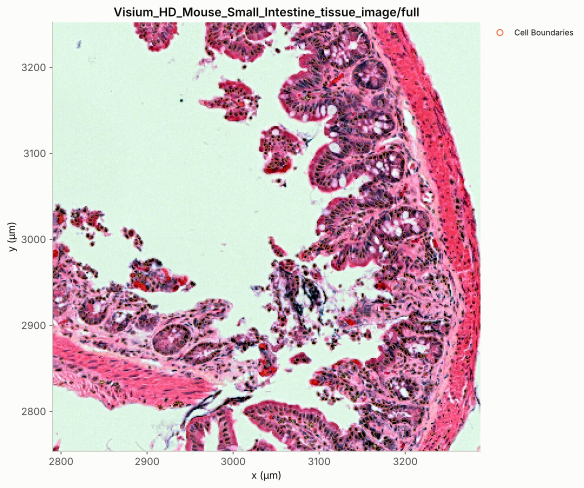

In [8]:
if HAVE_STARDIST:
    ab.pp.calculate_shape_metrics(mdata, modality='visium_hd_cells')
    print(mdata['visium_hd_cells'].obs[['cell_area', 'cell_circularity', 'n_bins']].describe())

    (
        ab.pl.image(mdata, modality='he')
        + ab.pl.boundaries(mdata, modality='visium_hd_cells')
    ).show()

## 5. From here, it's just cell x gene data

Once `visium_hd_cells` exists, nothing about it is Visium-HD-specific anymore — the normalize -> graph -> cluster -> plot pipeline from `01_core_workflow.ipynb` runs unchanged.

INFO:astrolabe.tl._graph:spatial_neighbors: 1080 cells, 18804 edges (mean degree 17.4) [generic]
INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 11 clusters


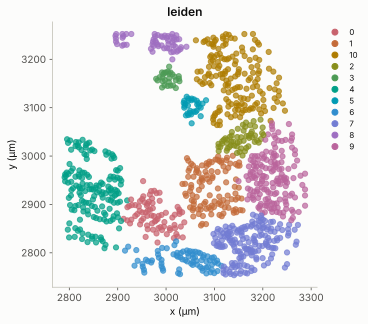

In [9]:
if HAVE_STARDIST and mdata['visium_hd_cells'].n_obs >= 10:
    ab.pp.normalize_total(mdata, modality='visium_hd_cells')
    ab.pp.log1p(mdata, modality='visium_hd_cells')
    ab.tl.spatial_neighbors(mdata, modality='visium_hd_cells')
    ab.tl.cluster(mdata, modality='visium_hd_cells', resolution=0.5)
    ab.pl.points(mdata, modality='visium_hd_cells', color='leiden').show()
else:
    print("Too few cells in the demo sub-region for a meaningful clustering pass — "
          "run this on the full tissue (drop the region_um restriction above) for real results.")

## 6. `pp.load_bin_counts` on its own — the lazy-materialization step, explicitly

Section 4 already used `pp.load_bin_counts(region_um=...)` in passing to scope the segmentation demo. On its own, it's the direct analog of `pp.extract_if_intensities` for a lazy IF/H&E image: the explicit "materialize this now" step, with the same two modes —

- `region_um=` or `bin_ids=` given: a partial `h5py` read, straight from the HDF5 matrix's CSC column layout (bins are the cheap axis to slice), scaling with the requested subset rather than the full matrix.
- neither given: a full `scanpy.read_10x_h5` load, with a logged warning naming the resulting shape.

`genes=` narrows either path further, without changing which bins are selected.

In [10]:
bins_tiny = mdata_tiny['visium_hd_bins']
coords = bins_tiny.obsm['spatial']
cx, cy = float(coords[:, 0].mean()), float(coords[:, 1].mean())
small_region = (cx - 100.0, cy - 100.0, cx + 100.0, cy + 100.0)

crop = ab.pp.load_bin_counts(bins_tiny, region_um=small_region, inplace=False)
print(f"{crop.n_obs} / {bins_tiny.n_obs} bins in a 200µm x 200µm crop; "
      f"X materialized: {crop.X is not None}, shape={crop.X.shape}")

anndata.py (1884): Variable names are not unique. To make them unique, call `.var_names_make_unique`.
INFO:astrolabe.pp._visium_hd:load_bin_counts: reading 10000 bins × 32285 genes from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\visium_hd_tiny\outs\binned_outputs\square_002um\filtered_feature_bc_matrix.h5


10000 / 330035 bins in a 200µm x 200µm crop; X materialized: True, shape=(10000, 32285)


## Where to go next

Visium HD slots into the rest of astrolabe the moment it becomes cell x gene data — either immediately (native Space Ranger segmentation) or after one `seg.assign_bins` call (bin2cell). Until then, the bin-level data behaves like any other lazy astrolabe resource: cheap metadata up front, real data only on request.

- *Quantifying spatial structure once you have cells* -> `02_spatial_statistics.ipynb`
- *Re-segmenting an imaging platform's own boundaries the same way `seg.segment_stardist` was used here* -> `05_segmentation_and_crop.ipynb`
- *Reading per-cell image intensities from H&E/IF once boundaries exist* -> `04_if_and_he_images.ipynb`